# scLATCH on PBMC (pseudotime-only, no condition)

The identical scLATCH pipeline as the huang tutorial, on human PBMC with no experimental
condition: only the config values change. It trains a pseudotime-only A(tau) model. See
`sclatch_tutorial.ipynb` for the full explanations. The bundled `data/pbmc_10k/` (1200 cells,
all 21,960 genes, precomputed mask) runs offline.


## 0. Formulation

scLATCH is a conditional diffusion model whose adjacency A is the GRN; a low-rank pseudotime-
and condition-gated term gives A(tau, k). With no condition, A(tau) depends on pseudotime
only. The mask is multiome: ChIP-Atlas binding within 10 kb of the TSS intersected with
accessible scATAC over the SCENIC+ allTFs universe. Same method and code as huang.


## 1. Setup

Install a GPU build of PyTorch first, then `pip install -e ".[viz]"` (see Install in the
README; check `torch.cuda.is_available()`). Put the dataset in `data/<DATASET_NAME>/`
(`expression.h5ad`, `metadata.csv`, and `atac.h5ad` or the precomputed `atac_mask.npz`). Edit
the config; everything downstream uses it.


In [1]:
# ===================== EDIT ME for your dataset =====================
DATASET_NAME    = "pbmc_10k"        # folder under data/
ORGANISM        = "human"           # "human" or "mouse"
CONDITION_KEY   = None              # no experimental condition -> pseudotime-only A(tau)
ROOT_GENE       = "SELL"            # naive/least-differentiated marker (pseudotime root)
CANDIDATE_ROOTS = ["SELL", "CCR7", "TCF7", "IL7R", "CD34", "SPINK2"]
# ====================================================================

`CONDITION_KEY=None`, so scLATCH trains pseudotime-only A(tau) and `model.conditions()`
is empty. The condition-only analyses (`delta_S`, differential network between conditions, the
condition showcase) are omitted; all the tau-dynamics apply.


In [2]:
import warnings, os
warnings.filterwarnings("ignore")
os.environ.setdefault("PYTHONWARNINGS", "ignore")
import numpy as np
np.seterr(all="ignore")
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

## 2. Load, choose the root, preprocess (same recipe as huang)

In [3]:
import sclatch, pandas as pd, matplotlib.pyplot as plt

ds = sclatch.load_dataset(DATASET_NAME, organism=ORGANISM)

def marker_table(adata, genes, cond_series):
    X = adata.layers["counts"] if "counts" in adata.layers else adata.X
    out = {}
    for g in genes:
        if g not in adata.var_names:
            continue
        col = X[:, adata.var_names.get_loc(g)]
        col = col.toarray().ravel() if hasattr(col, "toarray") else np.asarray(col).ravel()
        col = np.log1p(col)
        out[g] = {c: float(col[cond_series.values == c].mean()) for c in cond_series.unique()}
    return pd.DataFrame(out).T

group_key = CONDITION_KEY if (CONDITION_KEY and CONDITION_KEY in ds.metadata.columns) else "cell_type"
mt = marker_table(ds.adata, CANDIDATE_ROOTS, ds.metadata[group_key])
print(f"mean log1p expression per {group_key} (pick the marker highest in the start group):")
print(mt.round(3))

mean log1p expression per cell_type (pick the marker highest in the start group):
        CD4_T     NK      B  Mono_CD14  Mono_CD16    pDC
SELL    0.727  0.223  0.764      0.417      0.207  0.886
CCR7    0.693  0.127  0.403      0.091      0.032  0.000
TCF7    0.932  0.357  0.260      0.171      0.082  0.069
IL7R    1.215  0.507  0.207      0.177      0.061  0.069
CD34    0.000  0.000  0.000      0.000      0.000  0.000
SPINK2  0.013  0.014  0.000      0.006      0.000  0.000


The paper's PBMC benchmark used the default diffusion-pseudotime root: Fig 2 (static
networks) and Fig 3 (the commitment boundary, defined as where A reconfigures most, which is
direction-agnostic) do not depend on a polarized root. This notebook uses the recommended
marker-rooted approach with `ROOT_GENE="SELL"` (a naive / central-memory CD62L marker), which
is better practice.


In [4]:
ds = sclatch.preprocess(ds, root_gene=ROOT_GENE, organism=ORGANISM)

Direction check: the root gene must decrease along tau (Spearman rho < 0).

In [5]:
from scipy.stats import spearmanr
X = ds.adata[:, ROOT_GENE].X
expr = X.toarray().ravel() if hasattr(X, "toarray") else np.asarray(X).ravel()
m = expr > 0
rho, _ = spearmanr(ds.pseudotime[m], expr[m])
verdict = "correctly directed (decreases along tau)" if rho < 0 else "WRONG: increases along tau"
print(f"{ROOT_GENE} vs pseudotime  Spearman rho = {rho:+.3f}  ->  {verdict}")

SELL vs pseudotime  Spearman rho = -0.524  ->  correctly directed (decreases along tau)


## 3. Build the prior (mask)

The bundled data ships the precomputed real mask, so `build_prior` loads it offline (same call
as huang). The next cell shows the full recomputation from PBMC's own scATAC and the ChIP-Atlas
hg38 cache when they are present, and the overlap with the bundled mask. The bundled PBMC
mask was built with the SCENIC+ human TF list (the default `tf_list`), and
`allow_download=False` keeps the rebuild on the local ChIP-Atlas cache; a fresh clone without
those downloads skips it (the guard) and uses the bundled mask.


In [6]:
mask = sclatch.build_prior(ds, organism=ORGANISM)   # same call as huang
mask.shape

(21960, 21960)

In [7]:
# Recompute the mask from raw inputs to SHOW the full calculation. Guarded so a bare
# offline clone (no ChIP-Atlas cache, no atac.h5ad) still runs: it prints the fallback line.
# Recompute reads the TF list and TSS from priors/, the ChIP-Atlas cache from
# priors/chip_atlas/<genome>/, and the dataset's own scATAC from data/<DATASET_NAME>/atac.h5ad.
import glob
from scipy.sparse import load_npz, csr_matrix
_genome = {"mouse": "mm10", "human": "hg38"}[ORGANISM]
_have_cache = bool(glob.glob(f"priors/chip_atlas/{_genome}/*.tsv"))
_have_atac  = os.path.exists(f"data/{DATASET_NAME}/atac.h5ad")
if _have_cache and _have_atac:
    # the bundled PBMC mask was built with the SCENIC+ human TF list (the default)
    mask_rebuilt = sclatch.build_prior(ds, organism=ORGANISM, rebuild=True,
                                       allow_download=False)
    _rb = csr_matrix(mask_rebuilt > 0)                             # sparse bool (few edges)
    _bd = (load_npz(f"data/{DATASET_NAME}/atac_mask.npz") > 0)     # bundled, sparse bool
    _nr, _nb = int(_rb.nnz), int(_bd.nnz)
    _inter = int(_rb.multiply(_bd).nnz); _union = _nr + _nb - _inter
    print(f"recomputed edges = {_nr:,} | bundled edges = {_nb:,} | "
          f"Jaccard = {_inter/_union:.3f} | recall(bundled) = {_inter/_nb:.3f}")
else:
    print(f"recompute skipped (offline default): needs data/{DATASET_NAME}/atac.h5ad and "
          f"priors/chip_atlas/{_genome}/*.tsv (see priors/README.md); using the bundled mask.")

  Building ATAC mask: 21960 genes, human (hg38)


  TF list: 1488 TFs (SCENIC+ human, allTFs_hg38.txt, 1892 total, 21960 genes in dataset)


  [Step 1] Getting TSS positions...


  Loading TSS from local file priors/tss/TSS_extend_1M.txt (offline)...


    TSS mapped from file: 15015/21960


...

    Edges:      3,283,896 (0.681%)


    TFs:        924


    Targets:    13179


    Saved: outputs/masks/pbmc_10k/atac_mask.npz (2.1 MB, was 1929 MB dense)


recomputed edges = 3,283,896 | bundled edges = 3,237,289 | Jaccard = 0.982 | recall(bundled) = 0.998


## 4. Train (exact paper config, pseudotime-only)

Training is device-aware: it uses a CUDA GPU when available and falls back to CPU otherwise (a
GPU is recommended for this step; CPU works but is slower).

In [8]:
from sclatch.training import FINAL_DYNAMIC_CONFIG
model = sclatch.train(ds, mask, condition_key=CONDITION_KEY)   # CONDITION_KEY=None -> tau-only
conditions = model.conditions()          # empty list for a pseudotime-only model
print("conditions:", conditions)

  Expression: 1200 cells × 21960 genes



--- Seed 42 ---


  training:   0%|                                             | 0/2000 [00:00<?]


  training:   2%|▍                | 50/2000 [00:20<13:13, loss=0.8202 adj_Δ=inf]


  training:   5%|▊                | 99/2000 [00:40<12:57, loss=0.8202 adj_Δ=inf]


  training:   7%|▊          | 147/2000 [01:00<12:48, loss=0.5481 adj_Δ=0.000048]


  training:  10%|█          | 195/2000 [01:21<12:36, loss=0.1447 adj_Δ=0.000050]


  training:  12%|█▎         | 242/2000 [01:41<12:23, loss=0.0048 adj_Δ=0.000023]


  training:  14%|█▍        | 289/2000 [02:01<12:07, loss=-0.0828 adj_Δ=0.000014]



conditions: []


## 5. Analyses (pseudotime-only)

Same analysis calls as huang. `cond0` is None here, so each reads out A(tau) with no condition.


strongest regulators: ['BCL11B', 'RUNX1', 'MAX', 'KDM4A', 'MEIS2', 'CNOT3', 'ETS1', 'TBX21']


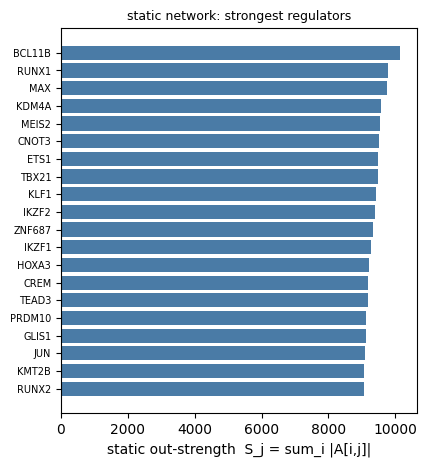

In [9]:
cond0 = conditions[0] if conditions else None   # None for a pseudotime-only model

sn = model.static_network(top_n_tfs=20)
print("strongest regulators:", list(sn.top.index[:8]))
fig, ax = plt.subplots(figsize=(4.6, 5)); sn.plot(ax); plt.show()

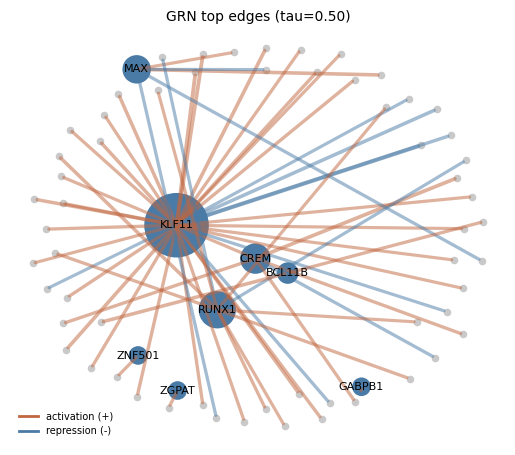

In [10]:
fig, ax = plt.subplots(figsize=(6.4, 5.4))
model.plot_network(condition=cond0, pseudotime=0.5, top_n_edges=60, ax=ax); plt.show()

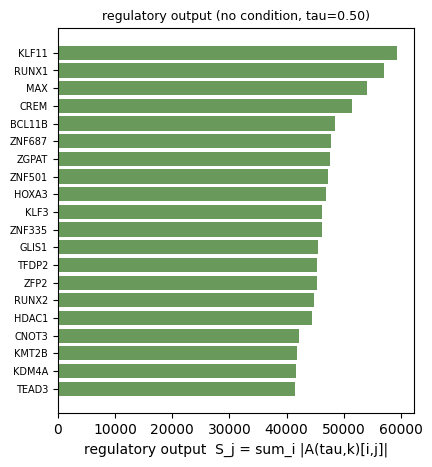

In [11]:
ro = model.regulatory_output(condition=cond0, top_n=20)
fig, ax = plt.subplots(figsize=(4.6, 5)); ro.plot(ax); plt.show()

max rewiring: 5.866


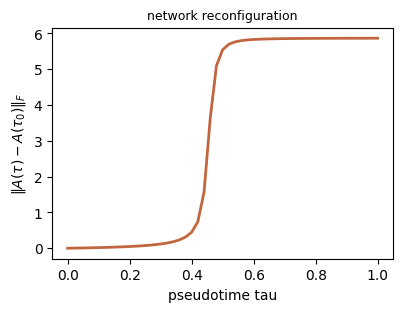

In [12]:
rc = model.reconfiguration_curve(condition=cond0)
print("max rewiring:", round(float(rc.frob.max()), 3))
fig, ax = plt.subplots(figsize=(4.4, 3)); rc.plot(ax); plt.show()

commitment boundary tau = 0.46


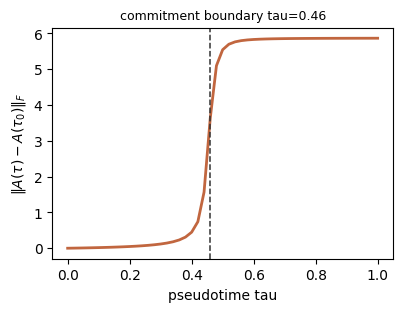

In [13]:
cb = model.commitment_boundary(condition=cond0)
print("commitment boundary tau =", round(cb.boundary, 3))
fig, ax = plt.subplots(figsize=(4.4, 3)); cb.plot(ax); plt.show()

knockout BCL11B | removed edges: (200, 4)


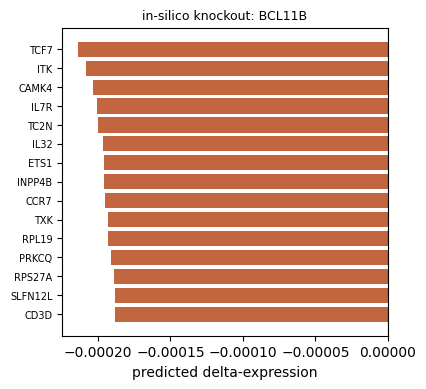

In [14]:
ko = model.knockout(sn.top.index[0], condition=cond0, top_n=15, return_network=True)
print("knockout", sn.top.index[0], "| removed edges:", ko.removed_edges.shape)
fig, ax = plt.subplots(figsize=(4.2, 4)); ko.plot(ax); plt.show()

U range: 0.0 to 3.55


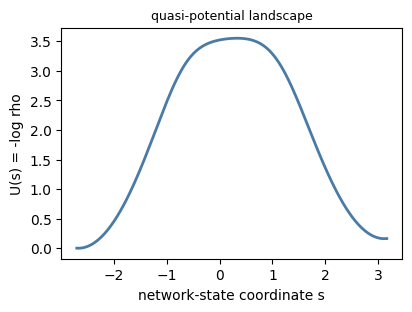

In [15]:
qp = model.quasi_potential(condition=cond0)
print("U range:", round(float(qp.potential.min()), 2), "to", round(float(qp.potential.max()), 2))
fig, ax = plt.subplots(figsize=(4.4, 3)); qp.plot(ax); plt.show()

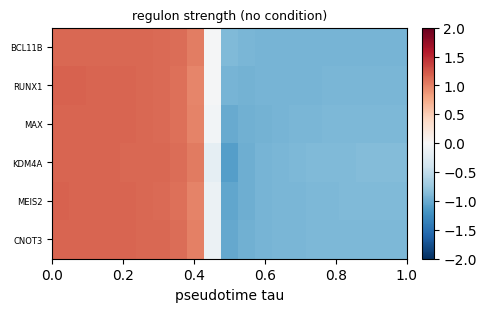

In [16]:
gh = model.gene_strength_heatmap(tfs=list(sn.top.index[:6]), condition=cond0)
fig, ax = plt.subplots(figsize=(5, 3)); gh.plot(ax); plt.show()

The condition-specific analyses (delta_S, differential network between conditions, the
condition showcase) are omitted here because this dataset has no condition.

## 7. Pseudotime dynamics and saving results

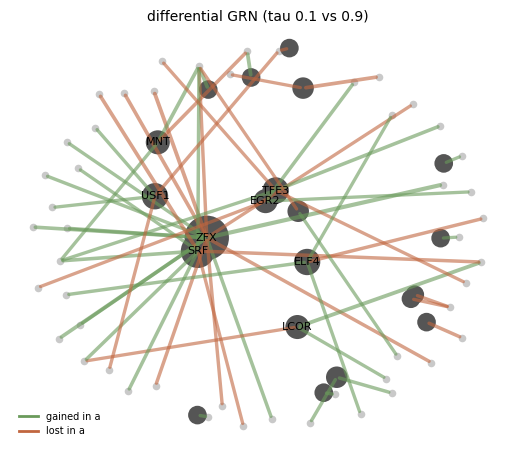

In [17]:
fig, ax = plt.subplots(figsize=(6.4, 5.4))
model.plot_differential_network(tau_a=0.1, tau_b=0.9, top_n_edges=60, ax=ax); plt.show()

  regulator_TF target_gene   weight_a   weight_b     change
0          ZFX        PKP4  34.227375  -6.952169  41.179544
1          ZFX        PIGB -39.769703  -2.272759 -37.496943
2         LCOR       ZC3H6  31.674536  -5.677291  37.351827
3        MECOM      MAP3K4  21.384367 -15.227737  36.612104
4          ZFX     TMEM243  32.325584  -3.651821  35.977405


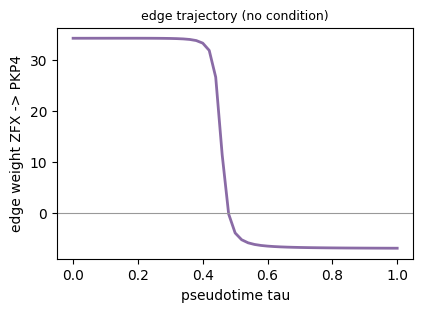

In [18]:
chg = model.top_changing_edges(tau_a=0.1, tau_b=0.9, top_n=5)
print(chg.head())
tf, target = chg.iloc[0]["regulator_TF"], chg.iloc[0]["target_gene"]
et = model.edge_trajectory(tf, target, condition=cond0)
fig, ax = plt.subplots(figsize=(4.6, 3)); et.plot(ax); plt.show()

In [19]:
snaps = model.network_snapshots(tau_grid=[0.1, 0.4, 0.7, 1.0], condition=cond0, top_n=200)
for t, df in snaps.items():
    print(f"tau={t}: {len(df)} edges, top: {df.iloc[0]['regulator_TF']} -> {df.iloc[0]['target_gene']}")

tau=0.1: 200 edges, top: TFE3 -> SLC34A1
tau=0.4: 200 edges, top: TFE3 -> SLC34A1
tau=0.7: 200 edges, top: HMGA1 -> RASGRP4
tau=1.0: 200 edges, top: HMGA1 -> RASGRP4


In [20]:
out_dir = model.save_results(f"outputs/{DATASET_NAME}_results")
print(open(os.path.join(out_dir, "RESULTS_README.md")).read())

saved 7 result files (2 static, 5 dynamic) + RESULTS_README.md -> outputs/pbmc_10k_results
# scLATCH results

Trained-network read-outs. Conditions: none (pseudotime-only model). A[target, regulator]; weights are grn-normalized. Files are split into `static/` and `dynamic/`.

## STATIC files

- `static/static_network.csv`: Static backbone A_static top edges. Columns: regulator_TF, target_gene, weight (grn-normalized A_static[target,regulator]), sign (+1 activation, -1 repression).
- `static/static_regulatory_output.csv`: Static per-TF out-strength S_j = sum_i |A_static[i,j]|. Columns: TF, S. Rank by S for the strongest regulators.

## DYNAMIC files

- `dynamic/dynamic_network_tau.csv`: A(tau) top edges at tau=0.5 (pseudotime-only model, no condition). Same columns as the static edge list.
- `dynamic/regulatory_output_over_tau.csv`: Per-TF regulatory output S_j(tau) over a pseudotime grid (rows = TFs, columns = tau). Pseudotime-only model.
- `dynamic/reconfiguration_curve.csv`: Network 

### Reload and use saved results (static + tau-only dynamic)

In [21]:
static_edges = pd.read_csv(os.path.join(out_dir, "static", "static_network.csv"))
print("STATIC static_network.csv reloaded:", static_edges.shape, "| top hub TFs:")
print(static_edges["regulator_TF"].value_counts().head(5).to_dict())
snap = np.load(os.path.join(out_dir, "dynamic", "tau_snapshots.npz"))
tau, W, reg, tgt = snap["tau"], snap["weights"], snap["regulator"], snap["target"]
print("\nDYNAMIC tau_snapshots.npz reloaded: weights", W.shape)
print(f"edge {reg[0]} -> {tgt[0]} weight across tau:",
      dict(zip(np.round(tau, 2).tolist(), np.round(W[0], 3).tolist())))

STATIC static_network.csv reloaded: (1000, 4) | top hub TFs:
{'BCL11B': 168, 'ETV6': 136, 'ETS1': 135, 'FOS': 97, 'TCF7': 81}

DYNAMIC tau_snapshots.npz reloaded: weights (200, 11)
edge KLF11 -> CBLC weight across tau: {0.0: -38.37, 0.1: -38.351, 0.2: -38.315, 0.3: -38.218, 0.4: -37.513, 0.5: -22.292, 0.6: -21.675, 0.7: -21.661, 0.8: -21.667, 0.9: -21.675, 1.0: -21.682}
